# CAFA–OMA preparation: minimum CAFA protein length 10 aa

Updated 5 November 2026 (length cutoff); earlier preparation update: 12 October 2026. Based on the downloaded `Oma_cafa_getting fastafiles.ipynb`; species collection restored from the project-folder version. Original notebooks are unchanged.

## Changes and retained behaviour

- CAFA proteins are retained only when their length is **at least 10 amino acids**. Exactly 10 aa is retained. The cutoff was changed from 15 to 10 aa on 5 November 2026.
- CAFA taxa with no retained proteins produce no FASTA and no CAFA tree leaf. The existing exclusion of taxon 147272 remains.
- Restored the species-collection cell before the species Venn diagram. It reads the generated CAFA filenames and requires them to match `test_new`. This fixes the undefined `cafa_sps`, `oma_sps`, and `tax2oma` variables.
- Length statistics now count **<10**, matching the filter, using a strict less-than comparison.
- The tree uses the retained CAFA taxa plus included OMA taxa. OMA sequences are not length-filtered here. An OMA genome may remain even if its corresponding CAFA file becomes empty.
- Kept only the final combined-input refresh cell, after tree saving and validation. It updates `fastoma_input` and removes obsolete numeric CAFA FASTAs. Existing original CAFA inputs are not modified. Generated output paths are unchanged.
- Existing tree construction, taxonomy repair, CAFA/OMA sister-leaf placement, protein mapping analyses, manifests, and validation are retained. No new composition rules or taxonomy-placement methods have been introduced.
- Earlier preparation cleared saved execution outputs. The 5 November cutoff edit does not rerun cells or update saved outputs; any existing outputs are historical.



In [1]:
from pathlib import Path as FilePath
from collections import Counter
import sys
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2, venn3
import matplotlib.colors as mcolors
import random
import seaborn as sns
from tqdm.auto import tqdm
from Bio import SeqIO
from IPython.display import display
import ete4
from ete4 import NCBITaxa

In [2]:
### Change the size of the plots
sns.set(context='notebook', style='ticks', palette='deep', font_scale=1.5, color_codes=False, rc=None) #font='arial', 

In [3]:
def load_fasta(inFile, tag):
    """Read CAFA records without silently overwriting duplicate IDs."""
    table = {}
    for record in SeqIO.parse(inFile, "fasta"):
        if tag == "test":
            fields = record.description.split()
            if len(fields) != 2:
                raise ValueError(f"Unexpected test header: {record.description}")
            pep, sp = fields
        elif tag == "train":
            pep = record.id.split("|")[1]
            sp = record.description.split("OX=", 1)[1].split()[0]
        else:
            raise ValueError(f"Unknown input type: {tag}")
        if not sp.isdigit():
            raise ValueError(f"Invalid taxon ID: {sp}")
        proteins = table.setdefault(sp, {})
        if pep in proteins:
            raise ValueError(f"Repeated protein {pep} in taxon {sp}")
        proteins[pep] = str(record.seq)
    print(f"Number of species loaded: {len(table)}")
    return table




In [5]:
### Paths — GenomeDK inputs and organised outputs

from pathlib import Path

FilePath = Path
import os
import re

root = Path(os.environ["WP1_ROOT"]).expanduser()
if not root.is_absolute():
    raise ValueError("WP1_ROOT must be an absolute workspace path")
stage = root / "HOGprop_validation_project/analysis/01_fastoma"
if not stage.is_dir():
    raise FileNotFoundError(stage)
run_id = os.environ["WP1_PREPARED_RUN_ID"]
if not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9._-]*", run_id):
    raise ValueError("Invalid WP1_PREPARED_RUN_ID")


# Original CAFA data.
cafa_dir = root / "input_raw/cafa6"

# Retained for later cells using f"{path}Test/...".
path = f"{cafa_dir}/"

testFasta = str(cafa_dir / "Test" / "testsuperset.fasta")
trainFasta = str(cafa_dir / "Train" / "train_sequences.fasta")
gotrainFile = str(cafa_dir / "Train" / "train_terms.tsv")

# Original exported OMA protein FASTAs and metadata.
oma_input_dir = root / "input_raw/oma_may2026"
omaSpeFile = str(oma_input_dir / "oma_species.tsv")

output_root = stage / "data" / run_id
reference_dir = root / "input_raw/reference"
prepared_dir = output_root / "prepared"
filtered_data_dir = prepared_dir / "filtered_data"
report_root = stage / "results" / run_id
plots_dir = report_root / "plots"
validation_dir = report_root / "input_validation"

original_taxa_file = reference_dir / "oma-species.txt"
omaTaxaFile = str(prepared_dir / "oma-species.txt")
mapping_file = reference_dir / "oma-uniprot.May2026.txt.gz"
taxonomy_db = reference_dir / "taxa.sqlite"
luca_source = reference_dir / "LUCA.h5"

# Generated CAFA FASTAs and species-tree outputs.
outpath = f"{prepared_dir / 'irene_proteome'}/"
outSpeciesFile = str(prepared_dir / "irene_species_tree.nwk")
outNodeFile = str(prepared_dir / "irene_species_tree_node2name.tsv")
gotrainOutFile = str(prepared_dir / "irene_train_terms_newID.tsv")
feaFile = str(prepared_dir / "irene_species_features.tsv")

# Plots: retain the trailing slash for existing plotting cells.
outplotPath = f"{plots_dir}/"

# Species provenance and overlapping-file tables.
manifest_file = prepared_dir / "irene_species_manifest.tsv"
overlap_file = prepared_dir / "irene_overlapping_species.tsv"
fasta_pairs_file = prepared_dir / "irene_cafa_oma_fasta_pairs.tsv"

excluded_taxids = {"147272"}

# Verify inputs before creating output directories.
required_inputs = [
    testFasta,
    trainFasta,
    gotrainFile,
    cafa_dir / "Test" / "testsuperset-taxon-list.tsv",
    omaSpeFile,
    original_taxa_file,
    mapping_file,
    taxonomy_db,
    luca_source,
]

missing = [
    str(filename)
    for filename in required_inputs
    if not FilePath(filename).is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing input files:\n" + "\n".join(missing)
    )

# Claim a new run directory before writing any derived files.
output_root.mkdir(exist_ok=False)
report_root.mkdir(exist_ok=False)

for directory in (
    outpath,
    prepared_dir,
    filtered_data_dir,
    plots_dir,
    validation_dir,
):
    FilePath(directory).mkdir(parents=True, exist_ok=True)

import shutil
shutil.copyfile(original_taxa_file, omaTaxaFile)

print("CAFA inputs:", cafa_dir)
print("OMA FASTAs:", oma_input_dir)
print("Taxonomy mapping:", omaTaxaFile)
print("UniProt mapping:", mapping_file)
print("Prepared data:", prepared_dir)
print("Filtering reports:", filtered_data_dir)
print("Plots:", plots_dir)
print("FastOMA inputs:", output_root / "fastoma_input")



CAFA inputs: /faststorage/project/evomics_projects/ijulca/projects/hogprop_project/cafa-6-protein-function-prediction
OMA FASTAs: /home/saschabrown/evomics_projects/saschabrown/oma_full_database
Taxonomy mapping: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/reference/oma-species.txt
UniProt mapping: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/reference/oma-uniprot.May2026.txt.gz
Prepared data: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/prepared
Filtering reports: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/prepared/filtered_data
Plots: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/reports/plots
FastOMA inputs: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/fastoma_input


In [6]:
### Preview the input FASTA headers
from itertools import islice
from Bio import SeqIO

files = {
    "CAFA test": FilePath(testFasta),
    "CAFA train": FilePath(trainFasta),
    "OMA": oma_input_dir / "UC098.fa",
}

for label, filename in files.items():
    print(f"\n--- {label}: {filename.name} ---")

    if not filename.is_file():
        print("File not found:", filename)
        continue

    with filename.open() as handle:
        for record in islice(SeqIO.parse(handle, "fasta"), 5):
            print("Protein ID:", record.id)
            print("Full header:", record.description)
            print()


--- CAFA test: testsuperset.fasta ---
Protein ID: A0A0C5B5G6
Full header: A0A0C5B5G6 9606

Protein ID: A0A1B0GTW7
Full header: A0A1B0GTW7 9606

Protein ID: A0JNW5
Full header: A0JNW5 9606

Protein ID: A0JP26
Full header: A0JP26 9606

Protein ID: A0PK11
Full header: A0PK11 9606


--- CAFA train: train_sequences.fasta ---
Protein ID: sp|A0A0C5B5G6|MOTSC_HUMAN
Full header: sp|A0A0C5B5G6|MOTSC_HUMAN Mitochondrial-derived peptide MOTS-c OS=Homo sapiens OX=9606 GN=MT-RNR1 PE=1 SV=1

Protein ID: sp|A0JNW5|BLT3B_HUMAN
Full header: sp|A0JNW5|BLT3B_HUMAN Bridge-like lipid transfer protein family member 3B OS=Homo sapiens OX=9606 GN=BLTP3B PE=1 SV=2

Protein ID: sp|A0JP26|POTB3_HUMAN
Full header: sp|A0JP26|POTB3_HUMAN POTE ankyrin domain family member B3 OS=Homo sapiens OX=9606 GN=POTEB3 PE=1 SV=2

Protein ID: sp|A0PK11|CLRN2_HUMAN
Full header: sp|A0PK11|CLRN2_HUMAN Clarin-2 OS=Homo sapiens OX=9606 GN=CLRN2 PE=1 SV=1

Protein ID: sp|A1A4S6|RHG10_HUMAN
Full header: sp|A1A4S6|RHG10_HUMAN Rho GTPas

## Getting the proteomes

In [7]:
test_seq = load_fasta(testFasta, 'test')
train_seq = load_fasta(trainFasta, 'train')

Number of species loaded: 8453
Number of species loaded: 1381


In [8]:
### Check training accessions, taxa and sequences against the CAFA superset
pep_test = {pep for proteins in test_seq.values() for pep in proteins}
pep_train = {pep for proteins in train_seq.values() for pep in proteins}
common = pep_train & pep_test
print("Test-superset proteins:", len(pep_test))
print("Training proteins:", len(pep_train))
print("Training IDs present in superset:", len(common))
print("Percentage of training IDs recovered:", 100 * len(common) / len(pep_train))
training_mismatches = [
    (sp, pep) for sp, proteins in train_seq.items() for pep, seq in proteins.items()
    if test_seq.get(sp, {}).get(pep) != seq
]
print("Training records with missing or different taxon/sequence:", len(training_mismatches))
assert not training_mismatches, f"Review training mismatches: {training_mismatches[:10]}"

Test-superset proteins: 224309
Training proteins: 82404
Training IDs present in superset: 82404
Percentage of training IDs recovered: 100.0
Training records with missing or different taxon/sequence: 0


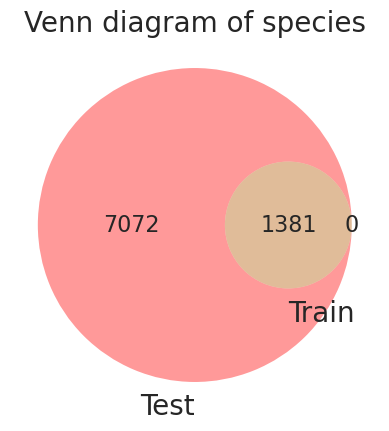

In [9]:
### Venn diagram for the species:
out = venn2([set(test_seq.keys()), set(train_seq.keys())], ('Test', 'Train'))

for text in out.set_labels:
    if text is not None: text.set_fontsize(20)
for text in out.subset_labels:
    if text is not None: text.set_fontsize(16)
plt.title("Venn diagram of species", size=20)
plt.savefig(f'{outplotPath}figure_species1.svg', bbox_inches='tight')# set_colors=("coral", "skyblue", "lightgreen"), alpha=0.9)
plt.show()

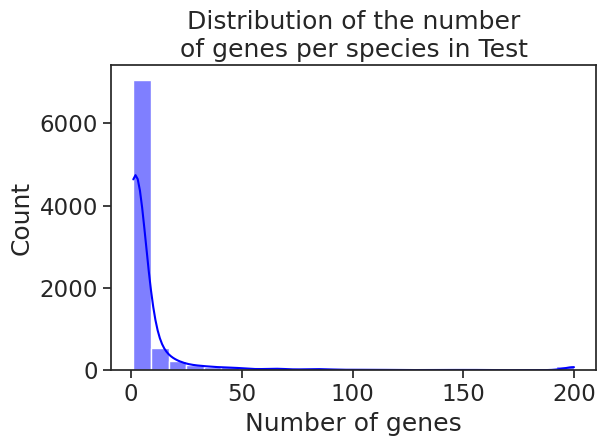

In [10]:
## Stats Number of proteins per species
test = []
for sp in test_seq:
    test.append(len(test_seq[sp]))

cap = 200
test = [x if x<cap else cap for x in test]

ax = sns.histplot(data=test, kde=True, color='blue', bins=25)
plt.title("Distribution of the number\nof genes per species in Test")
plt.xlabel('Number of genes')

plt.tight_layout()
plt.savefig(f'{outplotPath}figure_distribution_gene.svg', bbox_inches='tight')
plt.show()

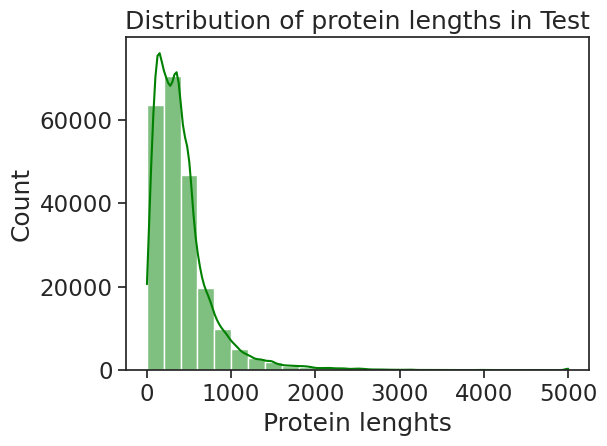

Number of proteins with a length <10 in test: 788 (0.35)


In [11]:
## Stats protein lengths
test = []
for sp in test_seq:
    for g in test_seq[sp]:
        test.append(len(test_seq[sp][g]))

cap = 5000
test = [x if x<cap else cap for x in test]

ax = sns.histplot(data=test, kde=True, color='green', bins=25)
plt.title("Distribution of protein lengths in Test")
plt.xlabel('Protein lenghts')

plt.tight_layout()
plt.savefig(f'{outplotPath}figure_distribution_length.svg', bbox_inches='tight')
plt.show()

m_len= 10
te_n = [x for x in test if x < m_len]
print(f'Number of proteins with a length <{m_len} in test: {len(te_n)} ({round(len(te_n)*100/len(test),2)})')

In [12]:
### Filter CAFA proteins and excluded taxa BEFORE writing FASTAs

minimum_length = 10
excluded_ids = set(map(str, excluded_taxids))

test_new = {}

for taxid, proteins in test_seq.items():
    taxid = str(taxid)

    if taxid in excluded_ids:
        continue

    retained = {
        accession: sequence
        for accession, sequence in proteins.items()
        if len(sequence) >= minimum_length
    }

    # Do not create a FASTA or CAFA tree leaf for an empty species.
    if retained:
        test_new[taxid] = retained

print("Retained CAFA species:", len(test_new))
print(
    "Retained CAFA proteins:",
    sum(len(proteins) for proteins in test_new.values()),
)

Retained CAFA species: 8421
Retained CAFA proteins: 223519


In [13]:
print("Training proteins retained:", sum(pep in pep_train for proteins in test_new.values() for pep in proteins))

Training proteins retained: 82334


In [14]:
tr, te = 0,0
for key, value in test_new.items():
    te += len(value.keys())
    tr += len(set([x for x in value if x in pep_train]))
print(f'Number of sequences in test dataset: {te}')
print(f'Number of sequences in train dataset: {tr}')

Number of sequences in test dataset: 223519
Number of sequences in train dataset: 82334


What we do now is that we is that we save the cafa protein files, as individual files on their own. 
So what we have fa. files for the OMA and for the Cafa dataset in the format that is needed for FastOMA. 

In [15]:
### Write filtered CAFA proteomes into the existing output folder

from pathlib import Path

proteome_dir = Path(outpath)
proteome_dir.mkdir(parents=True, exist_ok=True)

# Validate everything before removing old derived files.
assert test_new, "No retained CAFA species."
assert all(str(taxid).isdigit() for taxid in test_new)
assert all(proteins for proteins in test_new.values())
assert all(
    len(sequence) >= minimum_length
    for proteins in test_new.values()
    for sequence in proteins.values()
)

expected_files = {f"{taxid}.fa" for taxid in test_new}

# This folder should contain only generated CAFA protein FASTAs.
unexpected_files = [
    filename for filename in proteome_dir.glob("*.fa")
    if not filename.stem.isdigit()
]
if unexpected_files:
    raise ValueError(f"Unexpected non-CAFA FASTAs: {unexpected_files}")

# Remove stale CAFA files; retained filenames are overwritten below.
for filename in proteome_dir.glob("*.fa"):
    if filename.name not in expected_files:
        filename.unlink()

for taxid, proteins in test_new.items():
    destination = proteome_dir / f"{taxid}.fa"

    with destination.open("w") as handle:
        for accession, sequence in proteins.items():
            tag = "train" if accession in pep_train else "test"
            handle.write(f">{accession}_{taxid}_{tag}\n{sequence}\n")

actual_files = {filename.name for filename in proteome_dir.glob("*.fa")}
assert actual_files == expected_files

print("Filtered CAFA FASTAs written:", len(expected_files))
print("Minimum protein length:", minimum_length)
print("Folder:", proteome_dir)



Filtered CAFA FASTAs written: 8421
Minimum protein length: 10
Folder: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/prepared/irene_proteome


## Getting the species tree

#now we get the NCBI data base

In [16]:
ncbi = NCBITaxa(dbfile=str(taxonomy_db), update=False)
print("NCBI taxonomy database:", ncbi.dbfile)
# The taxonomy database is not updated automatically.

NCBI taxonomy database: /home/saschabrown/.local/share/ete/taxa.sqlite


OMA TSV is from new release and the taxa file is not, we have missing species now we test whether we or not we map these species.

In [17]:
# Column order documented in oma-species.txt.
oma_columns = [
    "oma_code",
    "oma_taxid",
    "ncbi_taxid",
    "gtdb_accession",
    "scientific_name",
    "genome_source",
    "release",
]

oma_metadata = pd.read_csv(
    omaTaxaFile,
    sep="\t",
    comment="#",
    header=None,
    names=oma_columns,
    dtype="string",
    keep_default_na=False,
)

# Standardise missing NCBI IDs in memory; the source file is unchanged.
oma_metadata["ncbi_taxid"] = (
    oma_metadata["ncbi_taxid"]
    .str.strip()
    .replace({
        "": pd.NA,
        "n/a": pd.NA,
        "NA": pd.NA,
        "None": pd.NA,
        "none": pd.NA,
    })
)




We list the species and we update our taxa file

In [18]:

# Original list of exported OMA genomes.
oma_export = pd.read_csv(
    omaSpeFile,
    sep="\t",
    dtype="string",
)

export_codes = set(oma_export["mnemonic"].str.strip())
mapping_codes = set(oma_metadata["oma_code"].str.strip())

without_mapping = oma_export[
    ~oma_export["mnemonic"].str.strip().isin(mapping_codes)
].copy()

mapping_only = oma_metadata[
    ~oma_metadata["oma_code"].str.strip().isin(export_codes)
].copy()

print("Exported genomes absent from mapping:", len(without_mapping))
print("Mapping entries absent from export:", len(mapping_only))

print(without_mapping)


Exported genomes absent from mapping: 0
Mapping entries absent from export: 0
Empty DataFrame
Columns: [mnemonic, taxid, scientific_name]
Index: []


In [19]:
### Append missing OMA mappings (backs up omaTaxaFile when run)
from pathlib import Path
from datetime import datetime
import shutil

taxa_file = Path(omaTaxaFile)
original = taxa_file.read_text()
existing_codes = {
    line.split("\t")[0].strip()
    for line in original.splitlines()
    if line.strip() and not line.startswith("#")
}
oma_export = pd.read_csv(omaSpeFile, sep="\t", dtype="string")
oma_export["mnemonic"] = oma_export["mnemonic"].str.strip()
if oma_export["mnemonic"].isna().any() or oma_export["mnemonic"].duplicated().any():
    raise ValueError("Missing or duplicate OMA codes in the export.")
missing = oma_export.loc[~oma_export["mnemonic"].isin(existing_codes)].copy()

# NCBI species-level mapping, including ERTm2 / ATCC PRA-371:

# The negative OMA ID is preserved in column 2, never copied to column 3.
manual_ncbi_mapping = {"NEMA1": 1913371}
rows, added, unresolved = [], [], []
for record in missing.itertuples(index=False):
    code = record.mnemonic
    raw_taxid = pd.to_numeric(record.taxid, errors="coerce")
    if pd.isna(raw_taxid) or raw_taxid % 1 != 0:
        unresolved.append((code, record.taxid, record.scientific_name))
        continue
    oma_taxid = int(raw_taxid)
    # Positive export taxonomy IDs are assumed to be NCBI IDs.
    ncbi_taxid = manual_ncbi_mapping.get(code, oma_taxid if oma_taxid > 0 else None)
    if ncbi_taxid is None:
        unresolved.append((code, oma_taxid, record.scientific_name))
        continue
    rows.append("\t".join([
        code, str(oma_taxid), str(ncbi_taxid), "n/a",
        str(record.scientific_name), "n/a", "n/a",
    ]))
    added.append((code, oma_taxid, ncbi_taxid, record.scientific_name))

if rows:
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup = taxa_file.with_name(f"{taxa_file.name}.{timestamp}.bak")
    shutil.copy2(taxa_file, backup)
    with taxa_file.open("a") as handle:
        if original and not original.endswith("\n"):
            handle.write("\n")
        handle.write("\n".join(rows) + "\n")
    print("Backup:", backup)

print("Entries added:", len(added))
display(pd.DataFrame(added, columns=["oma_code", "oma_taxid", "ncbi_taxid", "scientific_name"]))
print("Still unresolved:", len(unresolved))
if unresolved:
    display(pd.DataFrame(unresolved, columns=["oma_code", "oma_taxid", "scientific_name"]))

Entries added: 0


,oma_code,oma_taxid,ncbi_taxid,scientific_name


Still unresolved: 0


We now make a dual mapping between the two and list overlapping species, OMA can contains multiple species with the same taxon id and therefor there are less unique OMA then gene sequences. 
Later in the code this rectified at species tree levels

In [20]:
### Collect species from filtered CAFA files and OMA metadata
from pathlib import Path
from collections import defaultdict

cafa_sps = {p.stem for p in Path(outpath).glob("*.fa") if p.is_file()}
# Only the newly written, filtered CAFA files define CAFA tree taxa.
assert cafa_sps == set(map(str, test_new)), (
    "CAFA filenames differ from the filtered selection. Run the FASTA-writing cell first."
)
assert cafa_sps, "No retained CAFA species."
oma_metadata = pd.read_csv(
    omaTaxaFile, sep="\t", comment="#", header=None,
    names=oma_columns, dtype="string", keep_default_na=False,
)
oma_metadata["oma_code"] = oma_metadata["oma_code"].str.strip()
ids = pd.to_numeric(oma_metadata["ncbi_taxid"], errors="coerce")
invalid = ids.isna() | ids.le(0) | ids.mod(1).ne(0)
if invalid.any():
    display(oma_metadata.loc[invalid])
    raise ValueError("Resolve invalid NCBI IDs before building the tree.")
if oma_metadata["oma_code"].duplicated().any():
    raise ValueError("Repeated OMA codes in the taxonomy file.")
oma_metadata["ncbi_taxid"] = ids.astype("int64").astype(str)
tax2oma = defaultdict(set)
for row in oma_metadata.itertuples(index=False):
    if row.ncbi_taxid not in set(map(str, excluded_taxids)):
        tax2oma[row.ncbi_taxid].add(row.oma_code)
tax2oma = dict(tax2oma)
assert not (cafa_sps & set(map(str, excluded_taxids)))
oma_sps = set(tax2oma)
cafa_oma = sorted(cafa_sps & oma_sps, key=int)
print("CAFA taxa:", len(cafa_sps))
print("OMA genome entries:", len(oma_metadata))
print("OMA unique included taxa:", len(oma_sps))
print("Shared taxon IDs:", len(cafa_oma))


CAFA taxa: 8421
OMA genome entries: 2983
OMA unique included taxa: 2863
Shared taxon IDs: 623


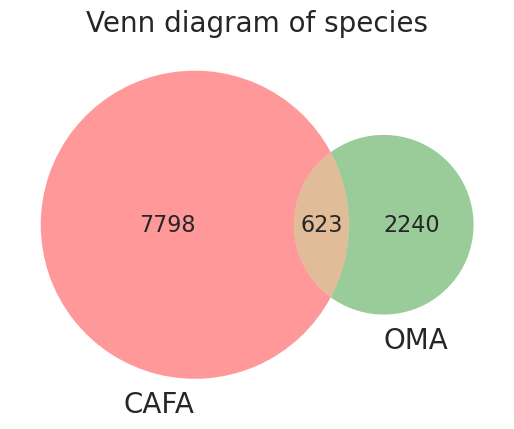

In [21]:
### Plotting a venn diagram with the included unique taxa:
out = venn2([cafa_sps, oma_sps], ('CAFA', 'OMA'))

for text in out.set_labels:
    if text is not None: text.set_fontsize(20)
for text in out.subset_labels:
    if text is not None: text.set_fontsize(16)
plt.title("Venn diagram of species", size=20)
plt.savefig(f'{outplotPath}figure_species2.svg', bbox_inches='tight')#, set_colors=("coral", "skyblue"), alpha=0.9)
plt.show()

In [22]:
### Match overlapping CAFA taxa to OMA genomes and their FASTA files

from pathlib import Path as FilePath
import pandas as pd

# Standardise identifiers without modifying the existing variables.
cafa_taxids = {str(taxid).strip() for taxid in cafa_sps}

oma_by_taxid = {}
for taxid, codes in tax2oma.items():
    taxid = str(taxid).strip()
    oma_by_taxid.setdefault(taxid, set()).update(
        str(code).strip() for code in codes
    )

shared_taxids = sorted(
    cafa_taxids & set(oma_by_taxid),
    key=int,
)

rows = []

for taxid in shared_taxids:
    cafa_fasta = FilePath(outpath) / f"{taxid}.fa"
    oma_codes = sorted(oma_by_taxid[taxid])

    for oma_code in oma_codes:
        oma_fasta = FilePath(oma_input_dir) / f"{oma_code}.fa"

        rows.append({
            "ncbi_taxid": taxid,
            "oma_code": oma_code,
            "oma_genomes_for_taxon": len(oma_codes),
            "cafa_fasta": str(cafa_fasta),
            "oma_fasta": str(oma_fasta),
            "cafa_fasta_found": cafa_fasta.is_file(),
            "oma_fasta_found": oma_fasta.is_file(),
        })

overlap_files = pd.DataFrame(
    rows,
    columns=[
        "ncbi_taxid",
        "oma_code",
        "oma_genomes_for_taxon",
        "cafa_fasta",
        "oma_fasta",
        "cafa_fasta_found",
        "oma_fasta_found",
    ],
)

# Identify pairs where both FASTA files exist.
overlap_files["both_files_found"] = (
    overlap_files["cafa_fasta_found"]
    & overlap_files["oma_fasta_found"]
)

ready_pairs = overlap_files.loc[
    overlap_files["both_files_found"]
].copy()

missing_files = overlap_files.loc[
    ~overlap_files["both_files_found"]
].copy()

# Save the complete correspondence table, including missing-file cases.
mapping_output = (
    fasta_pairs_file
)
mapping_output.parent.mkdir(parents=True, exist_ok=True)
overlap_files.to_csv(mapping_output, sep="\t", index=False)

print("Shared NCBI taxon IDs:", len(shared_taxids))
print("CAFA–OMA genome pairs:", len(overlap_files))
print("Pairs with both FASTA files:", len(ready_pairs))
print(
    "Shared taxa with multiple OMA genomes:",
    overlap_files.loc[
        overlap_files["oma_genomes_for_taxon"] > 1,
        "ncbi_taxid",
    ].nunique(),
)
print("Saved:", mapping_output)

display(overlap_files.head(20))

if not missing_files.empty:
    print("Pairs requiring missing files:")
    display(missing_files)

#good now we print the first file pairs, so we can see the different structure

from pathlib import Path as FilePath
from itertools import islice
from Bio import SeqIO

if ready_pairs.empty:
    raise ValueError("No shared CAFA–OMA pairs with both FASTA files found.")

pair = ready_pairs.iloc[0]

print("Shared NCBI taxon ID:", pair["ncbi_taxid"])
print("OMA genome code:", pair["oma_code"])
print("OMA genomes sharing this taxon:", pair["oma_genomes_for_taxon"])

for source, filename in [
    ("CAFA", pair["cafa_fasta"]),
    ("OMA", pair["oma_fasta"]),
]:
    filename = FilePath(filename)

    print(f"\n{'=' * 60}")
    print(source)
    print("File:", filename)

    protein_count = sum(1 for _ in SeqIO.parse(filename, "fasta"))
    print("Number of proteins:", protein_count)

    with filename.open() as handle:
        for record in islice(SeqIO.parse(handle, "fasta"), 3):
            print("\nProtein ID:", record.id)
            print("Full header:", record.description)
            print("Length:", len(record.seq), "aa")
            print("Sequence preview:", str(record.seq)[:80])

Shared NCBI taxon IDs: 623
CAFA–OMA genome pairs: 623
Pairs with both FASTA files: 623
Shared taxa with multiple OMA genomes: 0
Saved: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/irene_cafa_oma_fasta_pairs.tsv


,ncbi_taxid,oma_code,oma_genomes_for_taxon,cafa_fasta,oma_fasta,cafa_fasta_found,oma_fasta_found,both_files_found
0,2769,CHOCR,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
1,2880,ECTSI,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
2,3055,CHLRE,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
3,3067,VOLCA,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
4,3197,MARPO,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
5,3218,PHYPA,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
6,3311,GINBI,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
7,3330,PICGL,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
8,3332,PICSI,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True
9,3352,PINTA,1,/home/saschabrown/evomics_projects/saschabrown...,/home/saschabrown/evomics_projects/saschabrown...,True,True,True


Shared NCBI taxon ID: 2769
OMA genome code: CHOCR
OMA genomes sharing this taxon: 1

CAFA
File: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/prepared/irene_proteome/2769.fa
Number of proteins: 27

Protein ID: P93762_2769_train
Full header: P93762_2769_train
Length: 546 aa
Sequence preview: MATLPQKDPGYIVIDVNAGTPDKPDPRLPSMKQGFNRRWIGTNIDFVYVVYTPQGACTALDRAMEKCSPGTVRIVSGGHC

Protein ID: Q42480_2769_test
Full header: Q42480_2769_test
Length: 453 aa
Sequence preview: MTRSIVSLQVGQCGNQVGLKFWEGISAEHGIDVDGKYIGDRPDQELHRIGVYYNESSSGSYVPRAAMLDLEPGVLMAIKN

Protein ID: P48869_2769_test
Full header: P48869_2769_test
Length: 254 aa
Sequence preview: MNNILNFYPAVITTDVAENWQIGFQDPATPIMEGIINLHYDLMFFICVISVFVSWMLGRTLWHFEQNQNKIPSSLTHGTL

OMA
File: /home/saschabrown/evomics_projects/saschabrown/oma_full_database/CHOCR.fa
Number of proteins: 9550

Protein ID: CHOCR00001
Full header: CHOCR00001
Length: 489 aa
Sequence preview: MYFEDKLKLLLSSRHFLIYIFTNEEERLENTVNKIAKNEYPSNVYYWDFIDGFQN

Now we try to get the uniprot protein id and get the protein id from the Cafa proteins 

In [23]:
from Bio import SeqIO
import pandas as pd

rows = []

for record in SeqIO.parse(pair["cafa_fasta"], "fasta"):
    # Example: A0A0C5B5G6_9606_train
    parts = record.id.rsplit("_", 2)

    if len(parts) != 3:
        raise ValueError(f"Unexpected CAFA protein ID: {record.id}")

    uniprot_id, taxid, dataset = parts

    if dataset not in {"train", "test"}:
        raise ValueError(f"Unexpected dataset label: {record.id}")

    if taxid != str(pair["ncbi_taxid"]):
        raise ValueError(f"Unexpected taxon ID: {record.id}")

    rows.append({
        "cafa_protein_id": record.id,
        "uniprot_id": uniprot_id,
        "ncbi_taxid": taxid,
        "dataset": dataset,
        "sequence_length": len(record.seq),
    })

cafa_protein_ids = pd.DataFrame(
    rows,
    columns=[
        "cafa_protein_id",
        "uniprot_id",
        "ncbi_taxid",
        "dataset",
        "sequence_length",
    ],
)

uniprot_ids = cafa_protein_ids["uniprot_id"].drop_duplicates().tolist()

print("CAFA proteins:", len(cafa_protein_ids))
print("Unique UniProt accessions:", len(uniprot_ids))
display(cafa_protein_ids.head(20))

CAFA proteins: 27
Unique UniProt accessions: 27


,cafa_protein_id,uniprot_id,ncbi_taxid,dataset,sequence_length
0,P93762_2769_train,P93762,2769,train,546
1,Q42480_2769_test,Q42480,2769,test,453
2,P48869_2769_test,P48869,2769,test,254
3,P48932_2769_test,P48932,2769,test,250
4,P53499_2769_test,P53499,2769,test,373
5,P48691_2769_test,P48691,2769,test,467
6,P48866_2769_test,P48866,2769,test,532
7,P34919_2769_test,P34919,2769,test,414
8,P34920_2769_test,P34920,2769,test,335
9,P48878_2769_test,P48878,2769,test,253


In [24]:
from pathlib import Path
from Bio import SeqIO
import pandas as pd
import matplotlib.pyplot as plt

# 1. Find shared taxon IDs and their OMA genome codes.
cafa_taxids = {str(taxid) for taxid in cafa_sps}
oma_by_taxid = {
    str(taxid): set(codes)
    for taxid, codes in tax2oma.items()
}

shared_taxids = cafa_taxids & set(oma_by_taxid)

shared_oma_codes = {
    code
    for taxid in shared_taxids
    for code in oma_by_taxid[taxid]
}

if not shared_oma_codes:
    raise ValueError("No overlapping CAFA–OMA taxa found.")

print("Shared taxa:", len(shared_taxids))
print("Corresponding OMA genomes:", len(shared_oma_codes))

# 2. Collect OMA IDs with a UniProt accession for those genomes.
# Read the FULL mapping, not a table already filtered to CAFA proteins.
mapped_oma_ids = set()

for chunk in pd.read_csv(
    mapping_file,
    sep="\t",
    header=None,
    names=["oma_protein_id", "uniprot_identifier"],
    dtype="string",
    chunksize=500_000,
):
    genome_codes = chunk["oma_protein_id"].str[:5]

    matches = chunk.loc[
        genome_codes.isin(shared_oma_codes)
        & ~chunk["uniprot_identifier"].str.contains(
            "_", regex=False, na=True
        )
    ]

    mapped_oma_ids.update(matches["oma_protein_id"])

# 3. Count proteins actually present in each exported OMA FASTA.
genome_rows = []

for code in sorted(shared_oma_codes):
    filename = Path(oma_input_dir) / f"{code}.fa"

    if not filename.is_file():
        raise FileNotFoundError(filename)

    protein_ids = [
        record.id for record in SeqIO.parse(filename, "fasta")
    ]

    if not protein_ids:
        raise ValueError(f"Empty FASTA: {filename}")

    if len(protein_ids) != len(set(protein_ids)):
        raise ValueError(f"Duplicate protein IDs in {filename}")

    protein_ids = set(protein_ids)
    with_uniprot = len(protein_ids & mapped_oma_ids)

    genome_rows.append({
        "oma_code": code,
        "total_proteins": len(protein_ids),
        "with_uniprot": with_uniprot,
        "without_uniprot": len(protein_ids) - with_uniprot,
    })

oma_mapping_counts = pd.DataFrame(genome_rows)

# 4. Combine the counts across the overlapping genomes.
counts = pd.Series({
    "With UniProt accession": oma_mapping_counts["with_uniprot"].sum(),
    "Without UniProt accession": oma_mapping_counts["without_uniprot"].sum(),
})

total = int(oma_mapping_counts["total_proteins"].sum())
assert counts.sum() == total

display(oma_mapping_counts.head(20))
display(counts.to_frame("OMA proteins"))

# 5. Plot the combined counts.



Shared taxa: 623
Corresponding OMA genomes: 623


,oma_code,total_proteins,with_uniprot,without_uniprot
0,ABSGL,14891,14891,0
1,ACACA,14969,14969,0
2,ACAPL,16481,16481,0
3,ACTCC,33044,33042,2
4,ACTTE,19980,19959,21
5,ACYPI,33986,10528,23458
6,AEDAE,15113,15002,111
7,AEDAL,26843,14419,12424
8,AEGTA,33795,33762,33
9,AEGTS,45657,26651,19006


,OMA proteins
With UniProt accession,8650553
Without UniProt accession,2434378


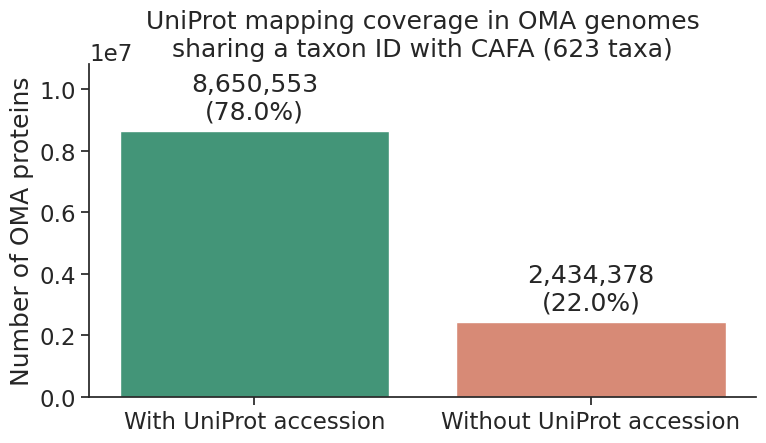

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    counts.index,
    counts.values,
    color=["#439578", "#D78A76"],
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,}\n({count / total:.1%})"
        for count in counts.values
    ],
    padding=5,
)

ax.set_ylabel("Number of OMA proteins")
ax.set_title(
    "UniProt mapping coverage in OMA genomes\n"
    f"sharing a taxon ID with CAFA ({len(shared_taxids):,} taxa)"
)
ax.set_ylim(0, max(counts.values) * 1.25)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
#save the figure
plt.savefig(f'{outplotPath}figure_oma_uniprot_mapping.svg')
plt.show()

,total,matched,unmatched,matched_percent
dataset,,,,
train,79110,70060,9050,88.56
test,97079,82374,14705,84.85


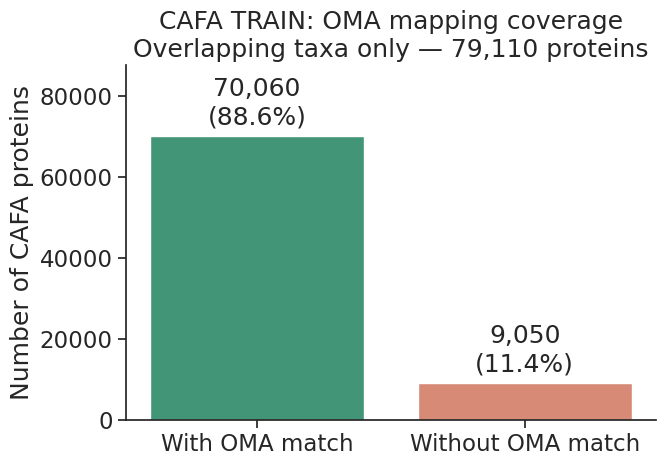

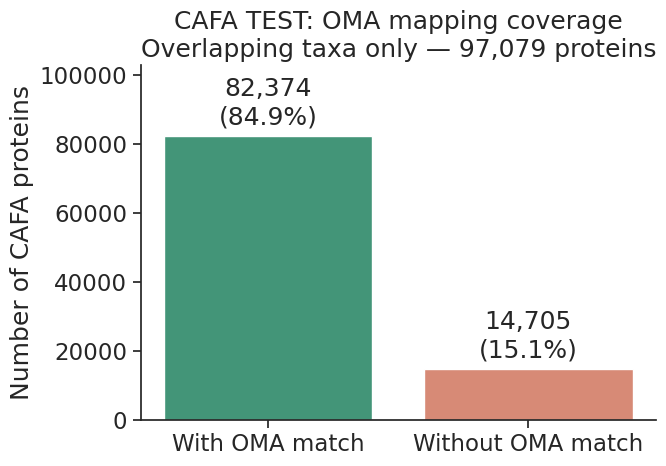

In [26]:
from pathlib import Path
from Bio import SeqIO
import pandas as pd
import matplotlib.pyplot as plt

# 1. Read CAFA proteins from overlapping taxa only.
cafa_rows = []

for taxid in sorted(shared_taxids, key=int):
    filename = Path(outpath) / f"{taxid}.fa"

    if not filename.is_file():
        raise FileNotFoundError(filename)

    for record in SeqIO.parse(filename, "fasta"):
        # Example: P93762_2769_train
        accession, header_taxid, dataset = record.id.rsplit("_", 2)

        if header_taxid != taxid or dataset not in {"train", "test"}:
            raise ValueError(f"Unexpected CAFA header: {record.id}")

        cafa_rows.append({
            "ncbi_taxid": taxid,
            "cafa_protein_id": record.id,
            "uniprot_id": accession,
            "dataset": dataset,
        })

cafa_shared = pd.DataFrame(cafa_rows)

if cafa_shared.empty:
    raise ValueError("No CAFA proteins found for the overlapping taxa.")

if cafa_shared.duplicated(["ncbi_taxid", "uniprot_id"]).any():
    raise ValueError("Repeated CAFA accessions within a taxon.")

# 2. Create the allowed taxon-to-OMA-genome relationships.
genome_links = pd.DataFrame([
    {"ncbi_taxid": taxid, "oma_code": code}
    for taxid in shared_taxids
    for code in oma_by_taxid[taxid]
])

# 3. Read UniProt mappings relevant to these CAFA accessions.
wanted_accessions = set(cafa_shared["uniprot_id"])
mapping_chunks = []

for chunk in pd.read_csv(
    mapping_file,
    sep="\t",
    header=None,
    names=["oma_protein_id", "uniprot_id"],
    dtype="string",
    chunksize=500_000,
):
    selected = chunk.loc[
        chunk["uniprot_id"].isin(wanted_accessions)
    ].copy()

    if not selected.empty:
        selected["oma_code"] = selected["oma_protein_id"].str[:5]
        mapping_chunks.append(selected)

if mapping_chunks:
    relevant_mapping = (
        pd.concat(mapping_chunks, ignore_index=True)
        .drop_duplicates()
    )
else:
    relevant_mapping = pd.DataFrame(
        columns=["oma_protein_id", "uniprot_id", "oma_code"]
    )

# 4. Match accessions, then require the correct species/genome.
candidate_matches = cafa_shared.merge(
    relevant_mapping,
    on="uniprot_id",
    how="inner",
)

candidate_matches = candidate_matches.merge(
    genome_links,
    on=["ncbi_taxid", "oma_code"],
    how="inner",
    validate="many_to_one",
)

# 5. Verify that the mapped OMA IDs occur in the exported FASTAs.
needed_oma_ids = set(candidate_matches["oma_protein_id"])
present_oma_ids = set()

for code in sorted(shared_oma_codes):
    filename = Path(oma_input_dir) / f"{code}.fa"

    if not filename.is_file():
        raise FileNotFoundError(filename)

    for record in SeqIO.parse(filename, "fasta"):
        if record.id in needed_oma_ids:
            present_oma_ids.add(record.id)

verified_matches = candidate_matches.loc[
    candidate_matches["oma_protein_id"].isin(present_oma_ids)
].drop_duplicates(["cafa_protein_id", "oma_protein_id"])

# 6. Mark each CAFA protein once, regardless of multiple OMA matches.
matched_cafa_ids = set(verified_matches["cafa_protein_id"])

cafa_shared["has_oma_match"] = (
    cafa_shared["cafa_protein_id"].isin(matched_cafa_ids)
)

# 7. Count matched and unmatched proteins separately for train/test.
summary = (
    cafa_shared.groupby("dataset")
    .agg(
        total=("cafa_protein_id", "size"),
        matched=("has_oma_match", "sum"),
    )
    .reindex(["train", "test"], fill_value=0)
)

summary["unmatched"] = summary["total"] - summary["matched"]
summary["matched_percent"] = (
    100 * summary["matched"] / summary["total"].replace(0, float("nan"))
).round(2)

display(summary)

# 8. Produce two plots.
for dataset in ["train", "test"]:
    counts = summary.loc[dataset, ["matched", "unmatched"]].astype(int)
    total = int(summary.loc[dataset, "total"])

    fig, ax = plt.subplots(figsize=(7, 5))

    bars = ax.bar(
        ["With OMA match", "Without OMA match"],
        counts.values,
        color=["#439578", "#D78A76"],
    )

    labels = [
        f"{count:,}\n({count / total:.1%})" if total else "0"
        for count in counts
    ]
    ax.bar_label(bars, labels=labels, padding=5)

    ax.set_ylabel("Number of CAFA proteins")
    ax.set_title(
        f"CAFA {dataset.upper()}: OMA mapping coverage\n"
        f"Overlapping taxa only — {total:,} proteins"
    )
    ax.set_ylim(0, max(1, counts.max()) * 1.25)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    #save the figure
    plt.savefig(f'{outplotPath}figure_cafa_oma_mapping_{dataset}.svg', bbox_inches='tight')
    plt.show()

,ncbi_taxid,total_cafa_proteins,matched_oma_proteins,fraction_matched
0,10020,2,1,0.500000
1,10029,248,203,0.818548
2,10090,17233,15340,0.890153
3,10116,8214,5617,0.683832
4,10117,6,5,0.833333
5,10141,305,232,0.760656
6,10160,6,5,0.833333
7,10181,6,6,1.000000
8,10228,23,22,0.956522
9,1026970,4,2,0.500000


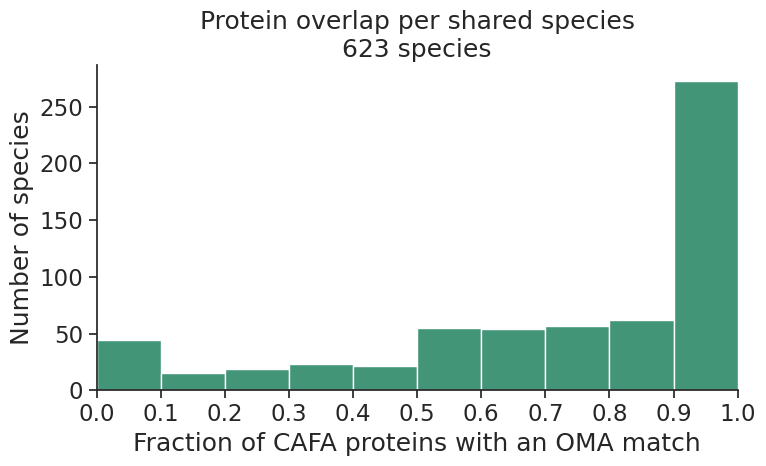

Mean fraction: 0.7279192514839646
Median fraction: 0.8405797101449275


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Count total and matched CAFA proteins for each species.
species_overlap = (
    cafa_shared.groupby("ncbi_taxid")
    .agg(
        total_cafa_proteins=("cafa_protein_id", "size"),
        matched_oma_proteins=("has_oma_match", "sum"),
    )
    .reset_index()
)

# 2. Calculate the fraction: for example, 3 / 10 = 0.3.
species_overlap["fraction_matched"] = (
    species_overlap["matched_oma_proteins"]
    / species_overlap["total_cafa_proteins"]
)

display(species_overlap.head(20))

# 3. Plot one fraction per species.
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    species_overlap["fraction_matched"],
    bins=np.linspace(0, 1, 11),
    color="#439578",
    edgecolor="white",
)

ax.set_xlabel("Fraction of CAFA proteins with an OMA match")
ax.set_ylabel("Number of species")
ax.set_title(
    "Protein overlap per shared species\n"
    f"{len(species_overlap):,} species"
)
ax.set_xticks(np.linspace(0, 1, 11))
ax.set_xlim(0, 1)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
#save the figure
plt.savefig(f'{outplotPath}figure_species_overlap_fraction.svg', bbox_inches='tight')
plt.show()

print("Mean fraction:", species_overlap["fraction_matched"].mean())
print("Median fraction:", species_overlap["fraction_matched"].median())

Species with mapped fraction < 0.3: 77
Unmapped CAFA proteins in these species: 1168


,Count,Mean,Median,Modes,Mode frequency,SD,Q1,Q3,IQR,Minimum,Maximum
Unmapped protein length (aa),1168,266.22,151.0,[37],18,368.52,72.0,348.25,276.25,10.0,4363.0
Total CAFA proteins per species,77,18.52,3.0,[1],30,32.77,1.0,21.00,20.00,1.0,164.0


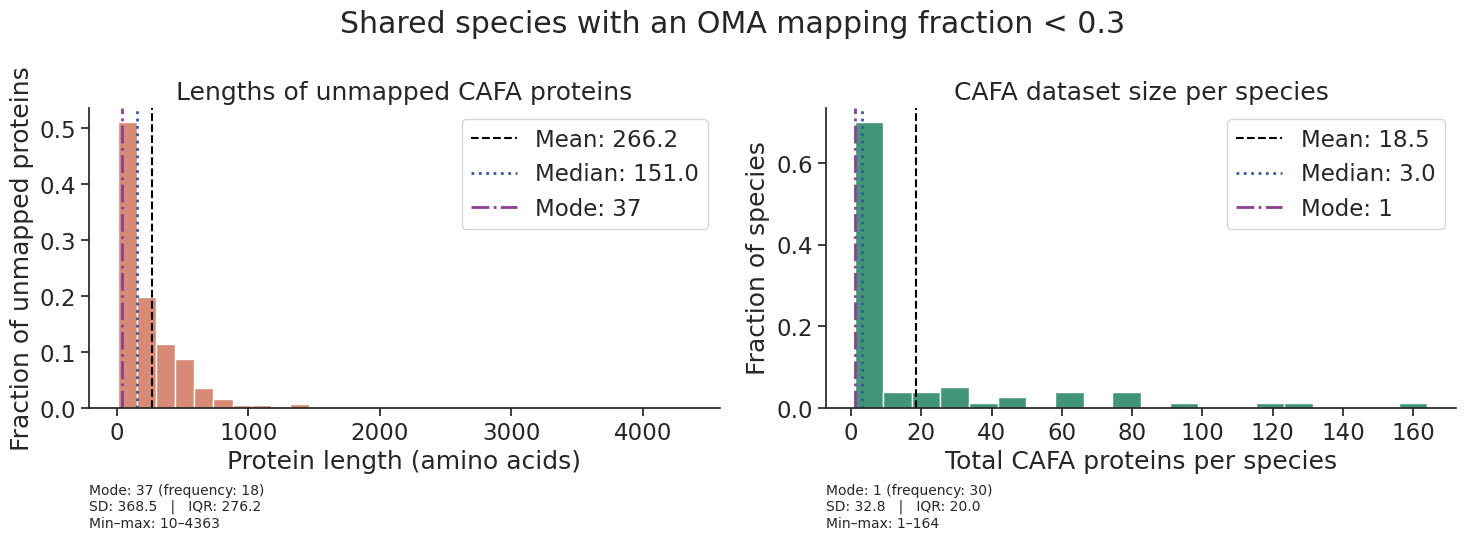

In [28]:
from pathlib import Path
from Bio import SeqIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Select shared species with fewer than 30% of CAFA proteins mapped.
# Change to 0.5 if you want the 50% threshold instead.
threshold = 0.3

low_overlap_species = species_overlap.loc[
    species_overlap["fraction_matched"] < threshold
].copy()

selected_taxids = set(
    low_overlap_species["ncbi_taxid"].astype(str)
)

# 2. Select unmapped CAFA proteins from these species.
unmapped = cafa_shared.loc[
    cafa_shared["ncbi_taxid"].astype(str).isin(selected_taxids)
    & ~cafa_shared["has_oma_match"]
].copy()

# 3. Read their sequence lengths.
unmapped_lengths = []
found_ids = set()

for taxid, group in unmapped.groupby("ncbi_taxid"):
    filename = Path(outpath) / f"{taxid}.fa"
    wanted_ids = set(group["cafa_protein_id"])

    if not filename.is_file():
        raise FileNotFoundError(filename)

    for record in SeqIO.parse(filename, "fasta"):
        if record.id in wanted_ids:
            if record.id in found_ids:
                raise ValueError(f"Duplicate protein ID: {record.id}")

            unmapped_lengths.append(len(record.seq))
            found_ids.add(record.id)

missing_ids = set(unmapped["cafa_protein_id"]) - found_ids
assert not missing_ids, (
    f"Proteins absent from FASTAs: {sorted(missing_ids)[:10]}"
)

# Total CAFA proteins per selected species, including mapped and unmapped.
protein_counts = low_overlap_species["total_cafa_proteins"].to_numpy()

print(f"Species with mapped fraction < {threshold}:",
      len(low_overlap_species))
print("Unmapped CAFA proteins in these species:", len(unmapped_lengths))


# 4. Calculate summary statistics.
def summarize(values):
    values = np.asarray(values, dtype=float)

    if len(values) == 0:
        return {
            "Count": 0,
            "Mean": np.nan,
            "Median": np.nan,
            "Modes": [],
            "Mode frequency": 0,
            "SD": np.nan,
            "Q1": np.nan,
            "Q3": np.nan,
            "IQR": np.nan,
            "Minimum": np.nan,
            "Maximum": np.nan,
        }

    unique_values, frequencies = np.unique(values, return_counts=True)
    maximum_frequency = frequencies.max()

    # Keep every mode if several values have the same highest frequency.
    modes = (
        unique_values[frequencies == maximum_frequency]
        .astype(int)
        .tolist()
    )

    q1, q3 = np.percentile(values, [25, 75])

    return {
        "Count": len(values),
        "Mean": values.mean(),
        "Median": np.median(values),
        "Modes": modes,
        "Mode frequency": int(maximum_frequency),
        "SD": values.std(ddof=1) if len(values) > 1 else np.nan,
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "Minimum": values.min(),
        "Maximum": values.max(),
    }


def format_modes(stats):
    modes = stats["Modes"]

    if not modes:
        return "No observations"

    if stats["Mode frequency"] == 1 and len(modes) > 1:
        return "No unique mode; all values occur once"

    text = ", ".join(map(str, modes[:5]))

    if len(modes) > 5:
        text += f" … ({len(modes)} tied modes)"

    return f'{text} (frequency: {stats["Mode frequency"]})'


length_stats = summarize(unmapped_lengths)
count_stats = summarize(protein_counts)

# The table retains all tied modes.
statistics = pd.DataFrame(
    [length_stats, count_stats],
    index=[
        "Unmapped protein length (aa)",
        "Total CAFA proteins per species",
    ],
)

display(statistics.round(2))


# 5. Plot normalized distributions.
# Bar heights sum to 1 within each plot.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_settings = [
    (
        axes[0],
        unmapped_lengths,
        length_stats,
        30,
        "#D78A76",
        "Lengths of unmapped CAFA proteins",
        "Protein length (amino acids)",
        "Fraction of unmapped proteins",
    ),
    (
        axes[1],
        protein_counts,
        count_stats,
        20,
        "#439578",
        "CAFA dataset size per species",
        "Total CAFA proteins per species",
        "Fraction of species",
    ),
]

for ax, values, stats, bins, color, title, xlabel, ylabel in plot_settings:
    values = np.asarray(values, dtype=float)

    if len(values):
        ax.hist(
            values,
            bins=bins,
            weights=np.full(len(values), 1 / len(values)),
            color=color,
            edgecolor="white",
        )

        ax.axvline(
            stats["Mean"],
            color="black",
            linestyle="--",
            label=f'Mean: {stats["Mean"]:.1f}',
        )

        ax.axvline(
            stats["Median"],
            color="#355C9A",
            linestyle=":",
            linewidth=2,
            label=f'Median: {stats["Median"]:.1f}',
        )

        # Draw a mode line only when there is a single mode.
        if len(stats["Modes"]) == 1:
            ax.axvline(
                stats["Modes"][0],
                color="#8C3F91",
                linestyle="-.",
                linewidth=2,
                label=f'Mode: {stats["Modes"][0]}',
            )

        ax.legend(loc="upper right")

        # Put spread statistics below the plot to avoid covering the bars.
        ax.text(
            0, -0.25,
            f"Mode: {format_modes(stats)}\n"
            f'SD: {stats["SD"]:.1f}   |   IQR: {stats["IQR"]:.1f}\n'
            f'Min–max: {stats["Minimum"]:.0f}–{stats["Maximum"]:.0f}',
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
        )
    else:
        ax.text(
            0.5, 0.5,
            "No observations",
            transform=ax.transAxes,
            ha="center",
            va="center",
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    f"Shared species with an OMA mapping fraction < {threshold}"
)

plt.tight_layout()
#save the figure
plt.savefig(f'{outplotPath}figure_species_low_overlap.svg', bbox_inches='tight')
plt.show()

### Temporary exclusion of Paspalum notatum (147272)
This is the previously agreed technical exclusion because its lineage was unavailable locally.
It is applied before FASTA export and to the tree-input sets. It is not evidence that the organism is incorrectly identified.

In [29]:
cafa_taxa = pd.read_csv(
    f"{path}Test/testsuperset-taxon-list.tsv",
    sep="\t"
)

print(cafa_taxa[cafa_taxa["ID"].astype(str) == "147272"])


try:
    lineage = ncbi.get_lineage(147272)
    print("Lineage:", lineage)
    print("Names:", ncbi.get_taxid_translator(lineage))
except ValueError as error:
    print(error)


          ID           Species
2552  147272  Paspalum notatum
Could not find taxid: 147272


### Build the taxonomy tree from the retained CAFA and included OMA taxa
Use the local NCBI taxonomy database. 


In [30]:
### Taxa for the species tree after CAFA filtering

species = sorted(cafa_sps | oma_sps, key=int)

assert species, "No species available for the tree."
assert not (set(species) & set(map(str, excluded_taxids)))

print("Unique NCBI taxon IDs for the tree:", len(species))

Unique NCBI taxon IDs for the tree: 10661


In [31]:

taxid2name = ncbi.get_taxid_translator(species)

tree = ncbi.get_topology(species)

Now some of them might be internal nodes and wrongly placed so we traverse the tree and find the number taxa id in the internal nodes. 
it sees whether it is in the species. Now if there any it add a child with node name. 


In [32]:
### Changing internal nodes
int_taxa = set()
t = tree.copy()
for node in t.traverse():
    if not node.is_leaf:
        taxaid = str(node.props['taxid'])
        if taxaid in species:
            int_taxa.add(taxaid)
            node = node.add_child(name=taxaid)
print(f'Number of CAFA taxaids in internal nodes added as leaves: {len(int_taxa)}')

Number of CAFA taxaids in internal nodes added as leaves: 288


Now the following code resolves the cafa taxa id's which are still not in the leafs.
What it does is that it convert into a scientific name and then back in NCBI id 


In [33]:
### Checking for more missing leaves:
leaves = list(t.leaf_names())

nofound = [x for x in species if x not in leaves]
print(f'Number of taxaids still missing: {len(nofound)}')
for taxid in nofound:
    taxid2name = ncbi.get_taxid_translator([taxid])
    name2taxid = ncbi.get_name_translator(list(taxid2name.values()))
    ntaxid = str(list(name2taxid.values())[0][0])
    n = ''
    for leaf in t.traverse():
        if leaf.name == ntaxid:
            n = leaf
    n = n.add_sister(name=taxid)


Number of taxaids still missing: 84


We do an additional test

In [34]:
### Check added leaves not present in the cafa dataset
for leaf in t:
    if leaf.name not in species:
        leaf.detach()
        

In [35]:
leaves = list(t.leaf_names())
nofound = [x for x in species if x not in leaves]
print(len(leaves), len(species))
print(f'Number of cafa taxaid not found {len(nofound)}')

10661 10661
Number of cafa taxaid not found 0


In [36]:
### Add OMA leaves while retaining CAFA leaves

i = 0

for leaf in list(t):
    name = leaf.name

    if name in tax2oma:
        sps = sorted(tax2oma[name])

        if name in cafa_sps:
            i += 1

            # Add OMA leaves directly beside the existing CAFA leaf.
            for sp in sps:
                leaf.add_sister(name=sp)

        else:
            if len(sps) == 1:
                leaf.name = sps[0]
            else:
                for sp in sps:
                    leaf.add_child(name=sp)

print(f"Overlapping taxa processed: {i}")

Overlapping taxa processed: 623


In [37]:
### Validate final labels after retaining both CAFA and OMA

from collections import Counter

# Use the taxa actually requested for this tree.
requested_taxids = set(map(str, species))

# Keep every requested CAFA label, including taxa also represented by OMA.
cafa_labels = set(map(str, cafa_sps)) & requested_taxids

# Include OMA genome codes for requested taxa.
oma_labels = {
    str(code)
    for taxid, codes in tax2oma.items()
    if str(taxid) in requested_taxids
    for code in codes
}

expected_labels = cafa_labels | oma_labels

leaf_labels = list(map(str, t.leaf_names()))
actual_labels = set(leaf_labels)

missing = sorted(expected_labels - actual_labels)
unexpected = sorted(actual_labels - expected_labels)
duplicates = {
    label: count
    for label, count in Counter(leaf_labels).items()
    if count > 1
}

print("Expected CAFA leaves:", len(cafa_labels))
print("Expected OMA genome leaves:", len(oma_labels))
print("Expected final leaves:", len(expected_labels))
print("Actual tree leaves:", len(leaf_labels))
print("Missing labels:", missing)
print("Unexpected labels:", unexpected)
print("Duplicate labels:", duplicates)

assert not missing and not unexpected and not duplicates, (
    "Final tree labels failed validation."
)

Expected CAFA leaves: 8421
Expected OMA genome leaves: 2983
Expected final leaves: 11404
Actual tree leaves: 11404
Missing labels: []
Unexpected labels: []
Duplicate labels: {}


In [38]:
# Check the root of the current tree.
print("Root label:", t.name)
print("Root NCBI taxon ID:", t.props.get("taxid", "Not stored"))
print("Root scientific name:", t.props.get("sci_name", "Not stored"))


Root label: 131567
Root NCBI taxon ID: 131567
Root scientific name: cellular organisms


In [39]:
i = 0
with open(outNodeFile, 'w') as fout:
    for node in t.traverse():
        if not node.is_leaf:
            i += 1
            name = f'NODE_{i}'
            if 'sci_name' in node.props:
                rank = str(node.props['sci_name'])
            else:
                rank = 'species_added'
            node.name = name
            print(f'{name}\t{rank}', file=fout)
            
# Replace the generated tree file on every execution; never append.
with open(outSpeciesFile, "w", encoding="utf-8") as tree_out:
    tree_out.write(t.write(format_root_node=True, parser=1))
print("Species tree overwritten:", outSpeciesFile)


#### Checking the tree and vizulizing the tree



Species tree overwritten: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/prepared/irene_species_tree.nwk


### Count NCBI, OMA and CAFA identifiers in the leaves
Inspect the current final tree `t`. Numeric CAFA labels are NCBI taxon IDs. OMA genome labels are mapped back to NCBI IDs when counting distinct taxa.


In [40]:
### Count identifiers among the leaves of the currently loaded tree t
# Run after loading the tree to inspect and defining cafa_sps and tax2oma.
# This cell reads t without changing the tree or writing any data files.
from collections import Counter
import pandas as pd

count_leaf_labels = [str(name) for name in t.leaf_names()]
count_cafa_ids = {str(taxid) for taxid in cafa_sps}
count_oma_to_taxid = {}
for taxid, codes in tax2oma.items():
    for code in codes:
        code, taxid = str(code), str(taxid)
        if code in count_oma_to_taxid and count_oma_to_taxid[code] != taxid:
            raise ValueError(f"Conflicting NCBI mappings for OMA code {code}")
        count_oma_to_taxid[code] = taxid

leaf_identifier_counts = pd.DataFrame({"leaf_label": count_leaf_labels})
leaf_identifier_counts["numeric_taxon_label"] = [
    label.isdigit() and int(label) > 0 for label in count_leaf_labels
]
leaf_identifier_counts["oma_code"] = [
    label in count_oma_to_taxid for label in count_leaf_labels
]
leaf_identifier_counts["cafa_taxon_id"] = [
    label in count_cafa_ids for label in count_leaf_labels
]
leaf_identifier_counts["represented_ncbi_taxid"] = [
    count_oma_to_taxid.get(label, label if label.isdigit() and int(label) > 0 else None)
    for label in count_leaf_labels
]

leaf_count_summary = pd.DataFrame([
    {"Identifier type": title,
     "Leaf entries": int(leaf_identifier_counts[column].sum()),
     "Unique labels": leaf_identifier_counts.loc[
         leaf_identifier_counts[column], "leaf_label"
     ].nunique()}
    for title, column in [
        ("Numeric taxon IDs (NCBI-style labels)", "numeric_taxon_label"),
        ("OMA codes found in mapping", "oma_code"),
        ("CAFA taxon IDs found in cafa_sps", "cafa_taxon_id"),
    ]
]).set_index("Identifier type")

print("Tree inspected: current t (the most recently loaded tree)")
print("Total leaf entries:", len(count_leaf_labels))
print("Unique leaf labels:", len(set(count_leaf_labels)))
display(leaf_count_summary)
print("Unique NCBI IDs represented (numeric labels + mapped OMA codes):",
      leaf_identifier_counts["represented_ncbi_taxid"].nunique())
print("Numeric leaf labels absent from the CAFA set:", int((
    leaf_identifier_counts["numeric_taxon_label"]
    & ~leaf_identifier_counts["cafa_taxon_id"]
).sum()))
print("CAFA IDs are NCBI IDs: the numeric and CAFA counts overlap.")
print("Numeric format alone does not verify an ID against the NCBI database.")

unclassified_leaves = leaf_identifier_counts.loc[
    ~leaf_identifier_counts[["numeric_taxon_label", "oma_code", "cafa_taxon_id"]].any(axis=1)
]
print("Unclassified leaf entries:", len(unclassified_leaves))
if not unclassified_leaves.empty:
    display(unclassified_leaves)
duplicate_leaf_counts = {label: count for label, count in
                         Counter(count_leaf_labels).items() if count > 1}
print("Duplicate leaf labels:", duplicate_leaf_counts)


Tree inspected: current t (the most recently loaded tree)
Total leaf entries: 11404
Unique leaf labels: 11404


,Leaf entries,Unique labels
Identifier type,,
Numeric taxon IDs (NCBI-style labels),8421,8421
OMA codes found in mapping,2983,2983
CAFA taxon IDs found in cafa_sps,8421,8421


Unique NCBI IDs represented (numeric labels + mapped OMA codes): 10661
Numeric leaf labels absent from the CAFA set: 0
CAFA IDs are NCBI IDs: the numeric and CAFA counts overlap.
Numeric format alone does not verify an ID against the NCBI database.
Unclassified leaf entries: 0
Duplicate leaf labels: {}


In [41]:
### Save species identifiers, overlap, and FASTA locations

from pathlib import Path
from collections import Counter
import pandas as pd

# 1. Normalize the identifiers used to build this tree.
requested_ids = set(map(str, species))
cafa_ids = set(map(str, cafa_sps)) & requested_ids

oma_by_taxid = {
    str(taxid): sorted(set(map(str, codes)))
    for taxid, codes in tax2oma.items()
    if str(taxid) in requested_ids and codes
}

shared_ids = cafa_ids & set(oma_by_taxid)

# Reverse mapping: OMA genome code -> NCBI taxon ID.
oma_to_ncbi = {}

for taxid, codes in oma_by_taxid.items():
    for code in codes:
        if code in oma_to_ncbi and oma_to_ncbi[code] != taxid:
            raise ValueError(f"Conflicting NCBI IDs for OMA code {code}")
        oma_to_ncbi[code] = taxid

# 2. Get names.
ncbi_names = ncbi.get_taxid_translator(
    [int(taxid) for taxid in requested_ids]
)

# Preserve OMA strain names where available.
oma_names = {
    str(row.oma_code).strip(): row.scientific_name
    for row in oma_metadata.itertuples(index=False)
}

# 3. Check that the final tree includes both sources as expected.
leaf_labels = list(map(str, t.leaf_names()))
expected_labels = cafa_ids | set(oma_to_ncbi)

duplicates = {
    label: count
    for label, count in Counter(leaf_labels).items()
    if count > 1
}

assert not duplicates, f"Duplicate tree labels: {duplicates}"
assert set(leaf_labels) == expected_labels, (
    f"Missing tree labels: "
    f"{sorted(expected_labels - set(leaf_labels))[:20]}\n"
    f"Unexpected tree labels: "
    f"{sorted(set(leaf_labels) - expected_labels)[:20]}"
)

# 4. One row per included FASTA/tree leaf.
rows = []

for label in leaf_labels:
    if label in oma_to_ncbi:
        source = "OMA"
        taxid = oma_to_ncbi[label]
        oma_id = label
        filename = Path(oma_input_dir) / f"{label}.fa"
        scientific_name = oma_names.get(
            label, ncbi_names.get(int(taxid), "")
        )
    else:
        source = "CAFA"
        taxid = label
        oma_id = pd.NA
        filename = Path(outpath) / f"{taxid}.fa"
        scientific_name = ncbi_names.get(int(taxid), "")

    rows.append({
        "tree_leaf": label,
        "ncbi_taxid": taxid,
        "scientific_name": scientific_name,
        "source": source,
        "oma_id": oma_id,
        "overlapping": taxid in shared_ids,
        "corresponding_oma_ids": ";".join(
            oma_by_taxid.get(taxid, [])
        ),
        "fasta_filename": filename.name,
        "fasta_location": str(filename.resolve()),
        "file_exists": filename.is_file(),
    })

species_manifest = pd.DataFrame(rows)

# 5. One row per overlapping NCBI taxon ID.
overlap_rows = []

for taxid in sorted(shared_ids, key=int):
    codes = oma_by_taxid[taxid]
    cafa_file = Path(outpath) / f"{taxid}.fa"
    oma_files = [
        Path(oma_input_dir) / f"{code}.fa"
        for code in codes
    ]

    overlap_rows.append({
        "ncbi_taxid": taxid,
        "scientific_name": ncbi_names.get(int(taxid), ""),
        "oma_ids": ";".join(codes),
        "cafa_fasta_location": str(cafa_file.resolve()),
        "oma_fasta_locations": ";".join(
            str(filename.resolve()) for filename in oma_files
        ),
        "all_files_exist": (
            cafa_file.is_file()
            and all(filename.is_file() for filename in oma_files)
        ),
    })

overlapping_species = pd.DataFrame(
    overlap_rows,
    columns=[
        "ncbi_taxid",
        "scientific_name",
        "oma_ids",
        "cafa_fasta_location",
        "oma_fasta_locations",
        "all_files_exist",
    ],
)

# 6. Save both tables in the reorganised prepared-data folder.
prepared_dir = Path(output_root) / "prepared"
prepared_dir.mkdir(parents=True, exist_ok=True)

manifest_file = prepared_dir / "irene_species_manifest.tsv"
overlap_file = prepared_dir / "irene_overlapping_species.tsv"

species_manifest.to_csv(
    manifest_file, sep="\t", index=False, na_rep=""
)
overlapping_species.to_csv(
    overlap_file, sep="\t", index=False, na_rep=""
)

print("Included FASTAs/tree leaves:", len(species_manifest))
print("Distinct NCBI IDs:", species_manifest["ncbi_taxid"].nunique())
print("Overlapping NCBI IDs:", len(overlapping_species))
print("\nSpecies manifest:", manifest_file)
print("Overlap table:", overlap_file)

display(species_manifest.head())
display(overlapping_species.head())

# Preserve the reports even if missing files need attention.
missing_files = species_manifest.loc[
    ~species_manifest["file_exists"]
]

if not missing_files.empty:
    display(missing_files)
    raise FileNotFoundError(
        f"{len(missing_files)} included FASTAs are missing; "
        "see the saved manifest."
    )

Included FASTAs/tree leaves: 11404
Distinct NCBI IDs: 10661
Overlapping NCBI IDs: 623

Species manifest: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/prepared/irene_species_manifest.tsv
Overlap table: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/data/prepared/irene_overlapping_species.tsv


,tree_leaf,ncbi_taxid,scientific_name,source,oma_id,overlapping,corresponding_oma_ids,fasta_filename,fasta_location,file_exists
0,MYCA1,243243,Mycobacterium avium (strain 104),OMA,MYCA1,False,MYCA1,MYCA1.fa,/faststorage/project/evomics_projects/saschabr...,True
1,MYCPA,262316,Mycolicibacterium paratuberculosis (strain ATC...,OMA,MYCPA,False,MYCPA,MYCPA.fa,/faststorage/project/evomics_projects/saschabr...,True
2,MYCIA,487521,Mycobacterium intracellulare (strain ATCC 1395...,OMA,MYCIA,False,MYCIA,MYCIA.fa,/faststorage/project/evomics_projects/saschabr...,True
3,MYCSS,164756,Mycobacterium sp. (strain MCS),OMA,MYCSS,False,MYCSS,MYCSS.fa,/faststorage/project/evomics_projects/saschabr...,True
4,MYCSJ,164757,Mycobacterium sp. (strain JLS),OMA,MYCSJ,False,MYCSJ,MYCSJ.fa,/faststorage/project/evomics_projects/saschabr...,True


,ncbi_taxid,scientific_name,oma_ids,cafa_fasta_location,oma_fasta_locations,all_files_exist
0,2769,Chondrus crispus,CHOCR,/faststorage/project/evomics_projects/saschabr...,/faststorage/project/evomics_projects/saschabr...,True
1,2880,Ectocarpus siliculosus,ECTSI,/faststorage/project/evomics_projects/saschabr...,/faststorage/project/evomics_projects/saschabr...,True
2,3055,Chlamydomonas reinhardtii,CHLRE,/faststorage/project/evomics_projects/saschabr...,/faststorage/project/evomics_projects/saschabr...,True
3,3067,Volvox carteri,VOLCA,/faststorage/project/evomics_projects/saschabr...,/faststorage/project/evomics_projects/saschabr...,True
4,3197,Marchantia polymorpha,MARPO,/faststorage/project/evomics_projects/saschabr...,/faststorage/project/evomics_projects/saschabr...,True


### Get feature file

In [42]:
ncbi = NCBITaxa(dbfile=str(taxonomy_db), update=False)
# ncbi.update_taxonomy_database()

In [43]:
t = ete4.Tree(outSpeciesFile, parser=1)
reloaded_labels = list(map(str, t.leaf_names()))
assert set(reloaded_labels) == expected_labels
assert len(reloaded_labels) == len(expected_labels)
all_node_names = [node.name for node in t.traverse()]
assert len(all_node_names) == len(set(all_node_names)), "Tree node names must be unique."
print("Saved Newick round-trip validated:", len(reloaded_labels), "leaves")

Saved Newick round-trip validated: 11404 leaves


In [44]:
### Refresh the combined FastOMA input folder

from pathlib import Path
from collections import Counter
import shutil
import filecmp
import ete4

input_dir = Path(output_root) / "fastoma_input"
combined_proteome_dir = input_dir / "proteome"

tree_source = Path(outSpeciesFile)
luca_destination = input_dir / "LUCA.h5"

for filename in (tree_source, luca_source):
    if not filename.is_file() or filename.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty input: {filename}")

# Use the newly saved tree.
saved_tree = ete4.Tree(str(tree_source), parser=1)
labels = list(map(str, saved_tree.leaf_names()))

duplicates = {
    label: count
    for label, count in Counter(labels).items()
    if count > 1
}
assert not duplicates, f"Duplicate tree leaves: {duplicates}"

cafa_ids = set(map(str, cafa_sps))
oma_codes = {
    str(code)
    for codes in tax2oma.values()
    for code in codes
}

assert not (cafa_ids & oma_codes), "CAFA and OMA labels collide."
assert set(labels) == cafa_ids | oma_codes, (
    "Saved tree does not match the current CAFA and OMA selection."
)

# Check source files before changing the combined folder.
sources = {}

for label in labels:
    source = (
        Path(outpath) / f"{label}.fa"
        if label in cafa_ids
        else Path(oma_input_dir) / f"{label}.fa"
    )

    if not source.is_file() or source.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty FASTA: {source}")

    sources[label] = source

input_dir.mkdir(parents=True, exist_ok=True)
combined_proteome_dir.mkdir(parents=True, exist_ok=True)

# Reject unexpected non-CAFA files rather than deleting them.
unexpected_oma_files = [
    filename
    for filename in combined_proteome_dir.glob("*.fa")
    if not filename.stem.isdigit() and filename.stem not in oma_codes
]
if unexpected_oma_files:
    raise ValueError(
        f"Unexpected files in the combined folder: {unexpected_oma_files}"
    )

# Verify existing OMA copies before reusing them.
filecmp.clear_cache()

for code in sorted(oma_codes):
    destination = combined_proteome_dir / f"{code}.fa"

    if destination.exists() and not filecmp.cmp(
        sources[code], destination, shallow=False
    ):
        raise ValueError(f"Existing OMA copy differs from its source: {destination}")

# Verify the existing reference database before reusing it.
if luca_destination.exists() and not filecmp.cmp(
    luca_source, luca_destination, shallow=False
):
    raise ValueError("Existing LUCA.h5 differs from the reference source.")

# Remove obsolete numeric CAFA files.
removed_files = 0

for filename in combined_proteome_dir.glob("*.fa"):
    if filename.stem.isdigit() and filename.stem not in cafa_ids:
        filename.unlink()
        removed_files += 1

# Overwrite all retained CAFA copies with their filtered versions.
for taxid in sorted(cafa_ids, key=int):
    destination = combined_proteome_dir / f"{taxid}.fa"
    shutil.copy2(sources[taxid], destination)

# Copy OMA files only if missing.
for code in sorted(oma_codes):
    destination = combined_proteome_dir / f"{code}.fa"
    if not destination.exists():
        shutil.copy2(sources[code], destination)

if not luca_destination.exists():
    shutil.copy2(luca_source, luca_destination)

# Replace the old species tree.
shutil.copy2(tree_source, input_dir / "species_tree.nwk")

# Check the final set of filenames.
actual_labels = {
    filename.stem
    for filename in combined_proteome_dir.glob("*.fa")
}

assert actual_labels == set(labels), (
    f"Missing FASTAs: {sorted(set(labels) - actual_labels)}\n"
    f"Unexpected FASTAs: {sorted(actual_labels - set(labels))}"
)

# Verify the refreshed CAFA copies.repair
filecmp.clear_cache()

for taxid in cafa_ids:
    destination = combined_proteome_dir / f"{taxid}.fa"
    assert filecmp.cmp(sources[taxid], destination, shallow=False), (
        f"CAFA copy differs: {destination}"
    )

print("Obsolete CAFA files removed:", removed_files)
print("Filtered CAFA files:", len(cafa_ids))
print("OMA files:", len(oma_codes))
print("Final FASTAs/tree leaves:", len(actual_labels))
print("Combined input folder:", input_dir)

Obsolete CAFA files removed: 0
Filtered CAFA files: 8421
OMA files: 2983
Final FASTAs/tree leaves: 11404
Combined input folder: /home/saschabrown/evomics_projects/saschabrown/HOGprop_validation_project/fastoma_input


### we count the number of species filtered out

In [45]:
### Collect species from filtered CAFA inputs and OMA metadata

from pathlib import Path
from collections import defaultdict
import pandas as pd

excluded_ids = set(map(str, excluded_taxids))

# Collect CAFA species remaining after filtering.
cafa_sps = set(map(str, test_new))

assert cafa_sps, "No retained CAFA species."
assert not (cafa_sps & excluded_ids)

# Check that written CAFA FASTAs match the filtered species.
expected_files = {f"{taxid}.fa" for taxid in cafa_sps}
actual_files = {
    filename.name
    for filename in Path(outpath).glob("*.fa")
}

assert actual_files == expected_files, (
    f"Missing CAFA files: {sorted(expected_files - actual_files)}\n"
    f"Unexpected CAFA files: {sorted(actual_files - expected_files)}"
)

# Reload the taxonomy file, including mappings added earlier.
oma_columns = [
    "oma_code",
    "oma_taxid",
    "ncbi_taxid",
    "gtdb_accession",
    "scientific_name",
    "genome_source",
    "release",
]

oma_metadata = pd.read_csv(
    omaTaxaFile,
    sep="\t",
    comment="#",
    header=None,
    names=oma_columns,
    dtype="string",
    keep_default_na=False,
)

oma_metadata["oma_code"] = oma_metadata["oma_code"].str.strip()
oma_metadata["ncbi_taxid"] = oma_metadata["ncbi_taxid"].str.strip()

# Require positive NCBI IDs.
valid_ids = oma_metadata["ncbi_taxid"].str.fullmatch(
    r"[1-9][0-9]*", na=False
)

if not valid_ids.all():
    display(oma_metadata.loc[~valid_ids])
    raise ValueError(
        "Resolve missing or invalid NCBI IDs before continuing."
    )

assert oma_metadata["oma_code"].ne("").all(), "Empty OMA codes."
assert not oma_metadata["oma_code"].duplicated().any(), (
    "Repeated OMA codes in the taxonomy mapping."
)

# Map each NCBI taxon ID to its OMA genome codes.
# Retain multiple OMA genomes sharing the same NCBI ID.
tax2oma = defaultdict(set)
name2taxa = {}

for record in oma_metadata.itertuples(index=False):
    taxid = record.ncbi_taxid
    code = record.oma_code

    if taxid in excluded_ids:
        continue

    tax2oma[taxid].add(code)
    name2taxa[code] = taxid

tax2oma = dict(tax2oma)
oma_sps = set(tax2oma)

# Verify that every included OMA genome has a non-empty FASTA file.
missing_oma_files = []

for code in sorted(name2taxa):
    filename = Path(oma_input_dir) / f"{code}.fa"

    if not filename.is_file() or filename.stat().st_size == 0:
        missing_oma_files.append(str(filename))

if missing_oma_files:
    raise FileNotFoundError(
        f"{len(missing_oma_files)} OMA FASTAs are missing or empty.\n"
        + "\n".join(missing_oma_files[:20])
    )

# Identify overlapping species using NCBI taxon IDs.
cafa_oma = sorted(cafa_sps & oma_sps, key=int)

print("Retained CAFA taxa:", len(cafa_sps))
print("Included OMA genomes:", len(name2taxa))
print("OMA unique included taxa:", len(oma_sps))
print("Shared taxon IDs:", len(cafa_oma))
print("Combined unique taxon IDs:", len(cafa_sps | oma_sps))

Retained CAFA taxa: 8421
Included OMA genomes: 2983
OMA unique included taxa: 2863
Shared taxon IDs: 623
Combined unique taxon IDs: 10661
